# Bayesian inference of Poisson distribution

Copyright (C) 2024 Hirokazu Maesaka, RIKEN SPring-8 Center. All rights reserved.

This program is free software: you can redistribute it and/or modify it under the terms of the GNU General Public License as published by the Free Software Foundation, either version 3 of the License, or (at your option) any later version.

This program is distributed in the hope that it will be useful, but WITHOUT ANY WARRANTY; without even the implied warranty of MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE. See the GNU General Public License for more details.

You should have received a copy of the GNU General Public License along with this program. If not, see <https://www.gnu.org/licenses/>.

In [1]:
import numpy as np
import scipy
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
# Parameters
mu = 2.0
alpha = 1.0
beta = 0.5
plt.rcParams['font.size'] = 16

## Poisson distribution
$$
P(k;\lambda) = \frac{\lambda^{k} e^{-\lambda}}{k!}
$$

In [3]:
poisson = scipy.stats.poisson(mu)

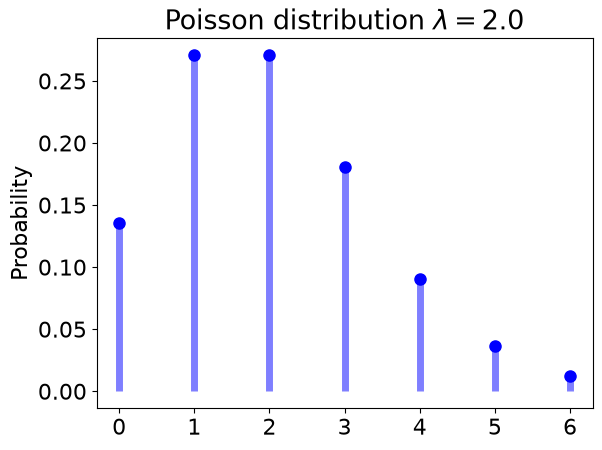

In [4]:

# Probability distribution
fig, ax = plt.subplots()
x = np.arange(0, poisson.ppf(0.99)+1)
pmf = poisson.pmf(x)
ax.plot(x, pmf, 'bo', ms=8, label='Poisson pmf')
ax.vlines(x, 0, pmf, colors='b', lw=5, alpha=0.5)
ax.set_title(f'Poisson distribution $\lambda={mu}$')
ax.set_ylabel('Probability')
plt.show()

## Gamma distribution
$$
f(\lambda;\alpha,\beta) = \frac{\beta^\alpha \lambda^{\alpha-1} e^{-\beta\lambda}}{\Gamma(\alpha)}
$$
- Conjugate prior of Poisson distribution

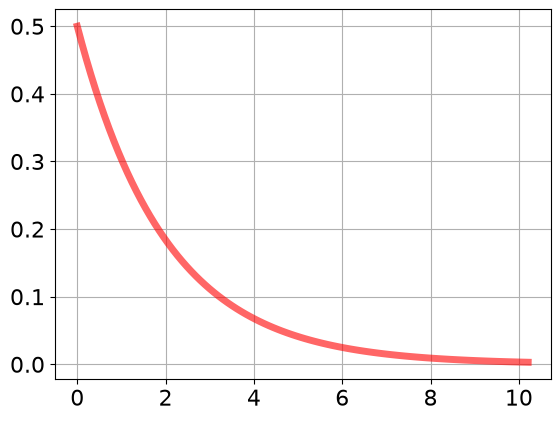

In [5]:
# Gamma distribution
gamma1 = scipy.stats.gamma(alpha, scale=1./beta)
fig, ax = plt.subplots()
x = np.linspace(0., gamma1.ppf(0.99)+1.0, 100)
ax.plot(x, gamma1.pdf(x), 'r-', lw=5, alpha=0.6, label='gamma pdf')
ax.grid()
plt.show()

## Random sampling of Poisson distribution

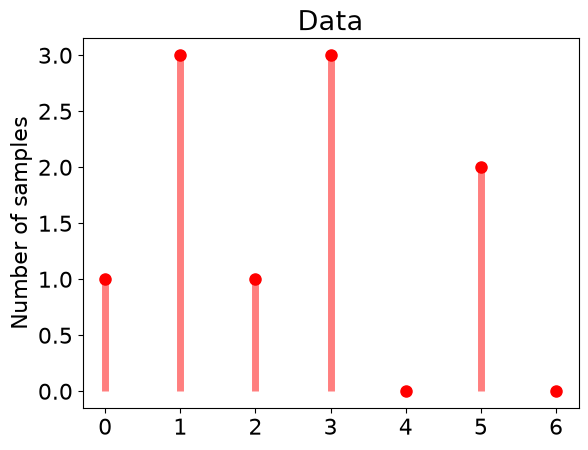

In [6]:
# sample n data points
n = 10
dat = poisson.rvs(size=n)
x = np.arange(poisson.ppf(0.01), poisson.ppf(0.99)+1)
hist, bins = np.histogram(dat, bins=len(x), range=(-0.5, len(x)+0.5))
fig, ax = plt.subplots()
ax.plot(x, hist, 'ro', ms=8, label='Data')
ax.vlines(x, 0, hist, colors='r', lw=5, alpha=0.5)
ax.set_title(f'Data')
ax.set_ylabel('Number of samples')
plt.show()

## Posterior distribution
$$
p(\lambda|\boldsymbol{k}) = \frac{(\beta+n)^{\alpha+\sum_{m=1}^{n}{k_m}} \lambda^{\alpha-1+\sum_{m=1}^{n}{k_m}} e^{-(\beta+n)\lambda}}{\Gamma\left(\alpha+\sum_{m=1}^{b}{k_m}\right)}
= f\left( \lambda ; \alpha+\sum_{m=1}^{n}{k_m}, \beta+n \right)
$$

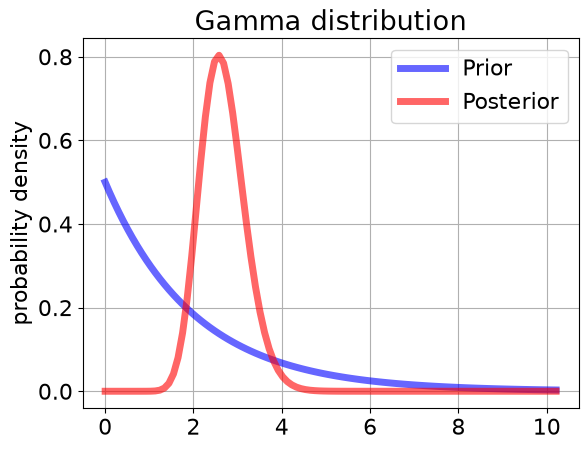

In [7]:
# Gamma distribution
gamma1 = scipy.stats.gamma(alpha, scale=1./beta)
gamma2 = scipy.stats.gamma(alpha+np.sum(dat), scale=1./(beta+n))
fig, ax = plt.subplots()
x = np.linspace(0., gamma1.ppf(0.99)+1.0, 100)
ax.plot(x, gamma1.pdf(x), 'b-', lw=5, alpha=0.6, label=f'Prior')
ax.plot(x, gamma2.pdf(x), 'r-', lw=5, alpha=0.6, label='Posterior')
ax.grid()
ax.legend()
ax.set_title('Gamma distribution')
ax.set_ylabel('probability density')
plt.show()

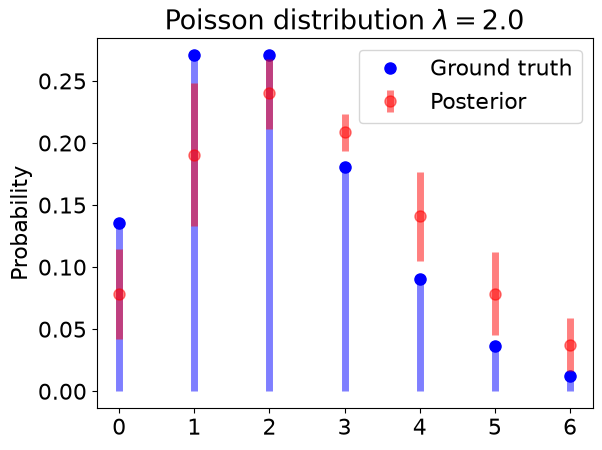

In [8]:
# Posterior distribution
x = np.arange(0, poisson.ppf(0.99)+1)
pmf = poisson.pmf(x)
pmean = np.empty_like(x)
plow = np.empty_like(x)
phigh = np.empty_like(x)
t = np.linspace(0.001,0.999,999)
for xx in x:
    i = int(xx)
    p = scipy.stats.poisson.pmf(i, gamma2.ppf(t))
    pp = np.sort(p)
    pmean[i] = np.mean(p)
    plow[i] = pmean[i] - pp[158]
    phigh[i] = pp[840] - pmean[i]
fig, ax = plt.subplots()
ax.plot(x, pmf, 'bo', ms=8, label='Ground truth')
ax.vlines(x, 0, pmf, colors='b', lw=5, alpha=0.5)
ax.errorbar(x, pmean, yerr=[plow,phigh], fmt='ro', ms=8, lw=5, alpha=0.5, label='Posterior')
ax.set_title(f'Poisson distribution $\lambda={mu}$')
ax.set_ylabel('Probability')
ax.legend()
plt.show()

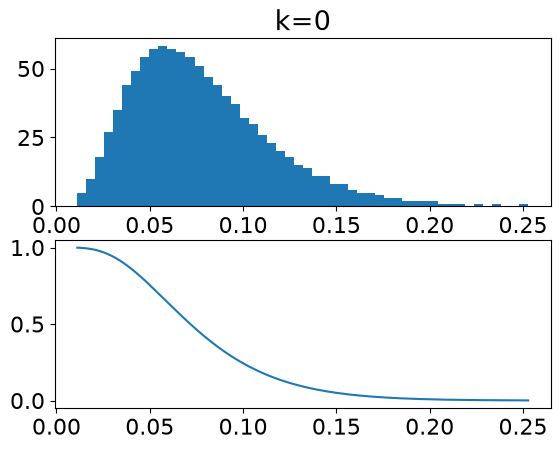

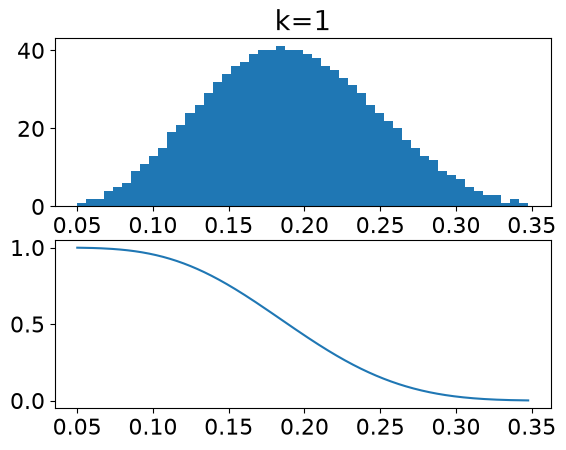

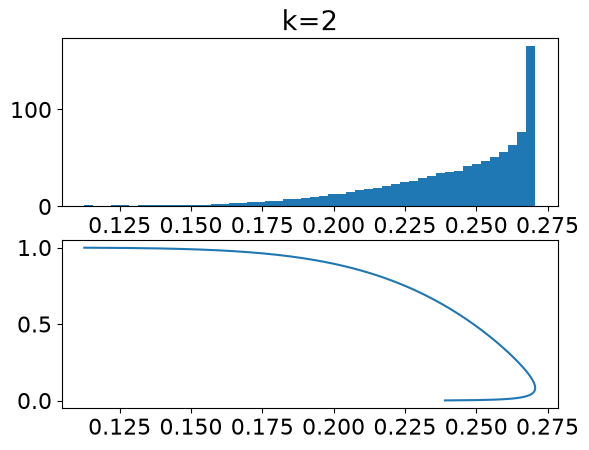

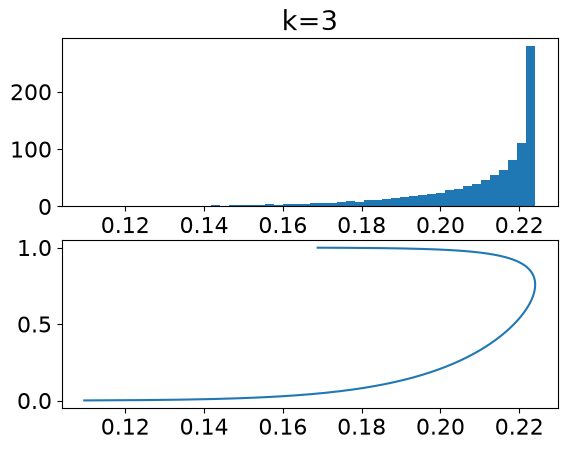

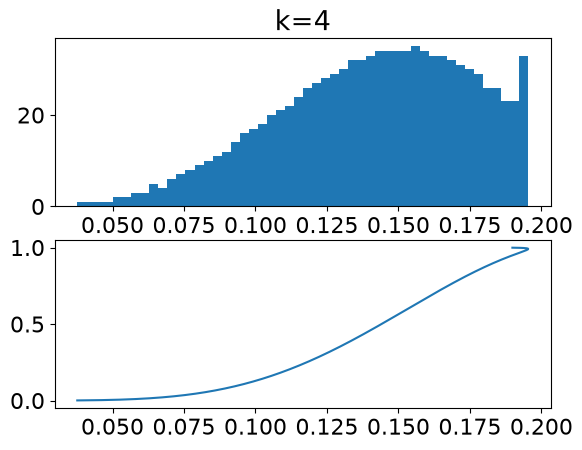

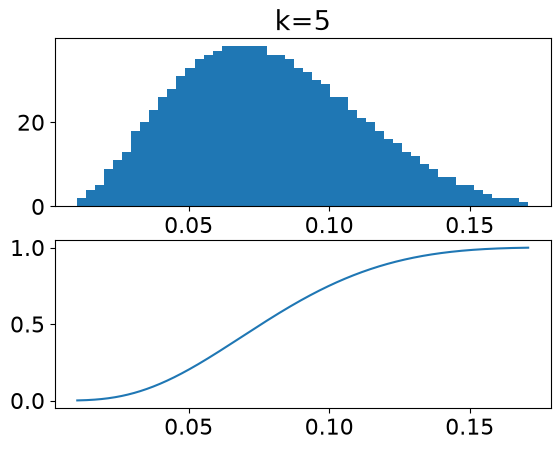

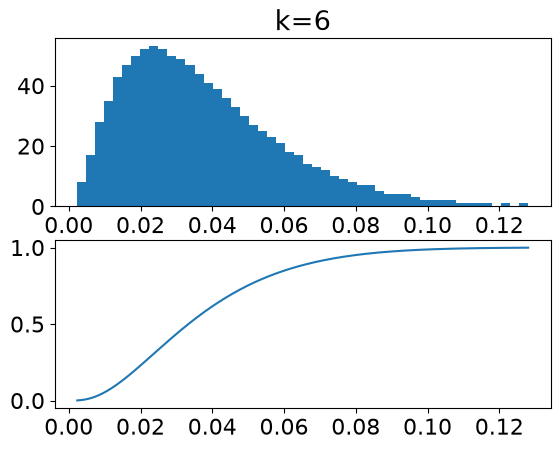

In [9]:
# Posteriors
t = np.linspace(0.001,0.999,999)
for xx in x:
    i = int(xx)
    p = scipy.stats.poisson.pmf(i, gamma2.ppf(t))
    fig, ax = plt.subplots(2,1)
    ax[0].hist(p, 50)
    ax[0].set_title(f'k={i}')
    ax[1].plot(p,t)
    plt.show()